In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


In [4]:
df = pd.read_csv("/content/Dataset.csv")
df

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2011,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0,3,13,16
1,2,01-01-2011,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.8,0,8,32,40
2,3,01-01-2011,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,?,0,5,27,32
3,4,01-01-2011,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0,3,10,13
4,5,01-01-2011,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,31-12-2012,springer,2012,12,19,No,1,Working Day,Mist,0.26,0.2576,0.6,0.1642,11,108,119
17375,17376,31-12-2012,springer,2012,12,20,No,1,Working Day,Mist,0.26,0.2576,0.6,0.1642,8,81,89
17376,17377,31-12-2012,springer,2012,12,21,No,1,Working Day,Clear,?,0.2576,0.6,0.1642,7,83,90
17377,17378,31-12-2012,springer,2012,12,22,No,1,Working Day,Clear,0.26,0.2727,0.56,0.1343,13,48,61


In [6]:
df.shape

(17379, 17)

In [7]:
df.columns.tolist()

['instant',
 'dteday',
 'season',
 'yr',
 'mnth',
 'hr',
 'holiday',
 'weekday',
 'workingday',
 'weathersit',
 'temp',
 'atemp',
 'hum',
 'windspeed',
 'casual',
 'registered',
 'cnt']

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   instant     17379 non-null  int64 
 1   dteday      17379 non-null  object
 2   season      17379 non-null  object
 3   yr          17379 non-null  object
 4   mnth        17379 non-null  object
 5   hr          17379 non-null  int64 
 6   holiday     17379 non-null  object
 7   weekday     17379 non-null  int64 
 8   workingday  17379 non-null  object
 9   weathersit  17379 non-null  object
 10  temp        17379 non-null  object
 11  atemp       17379 non-null  object
 12  hum         17379 non-null  object
 13  windspeed   17379 non-null  object
 14  casual      17379 non-null  object
 15  registered  17379 non-null  object
 16  cnt         17379 non-null  int64 
dtypes: int64(4), object(13)
memory usage: 2.3+ MB


In [9]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
instant,17379.0,NaN,NaN,NaN,8690.0,5017.0295,1.0,4345.5,8690.0,13034.5,17379.0
dteday,17379,731,31-12-2012,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,17379,5,fall,4496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
yr,17379,3,2012,8734,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mnth,17379,13,5,1488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hr,17379.0,NaN,NaN,NaN,11.546752,6.914405,0.0,6.0,12.0,18.0,23.0
holiday,17379,3,No,16878,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weekday,17379.0,NaN,NaN,NaN,3.003683,2.005771,0.0,1.0,3.0,5.0,6.0
workingday,17379,3,Working Day,11862,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weathersit,17379,5,Clear,11412,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
df.tail()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
17374,17375,31-12-2012,springer,2012,12,19,No,1,Working Day,Mist,0.26,0.2576,0.6,0.1642,11,108,119
17375,17376,31-12-2012,springer,2012,12,20,No,1,Working Day,Mist,0.26,0.2576,0.6,0.1642,8,81,89
17376,17377,31-12-2012,springer,2012,12,21,No,1,Working Day,Clear,?,0.2576,0.6,0.1642,7,83,90
17377,17378,31-12-2012,springer,2012,12,22,No,1,Working Day,Clear,0.26,0.2727,0.56,0.1343,13,48,61
17378,17379,31-12-2012,springer,2012,12,23,No,1,?,Clear,0.26,0.2727,0.65,0.1343,12,37,49


In [11]:

df = df.replace(r"^\s*\?\s*$", np.nan, regex=True)

print("Missing values in each column:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nTotal missing values:", df.isnull().sum().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Missing values in each column:


,0
temp,11
atemp,6
season,6
hum,6
windspeed,5
workingday,5
weathersit,4
yr,1
mnth,1
registered,1



Total missing values: 48

Duplicate rows: 0


In [12]:

numeric_columns = [
    "instant", "yr", "mnth", "hr", "weekday",
    "temp", "atemp", "hum", "windspeed",
    "casual", "registered", "cnt"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["dteday"] = pd.to_datetime(
    df["dteday"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("Updated data types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values after conversion:")
display(df.isnull().sum().sort_values(ascending=False))


Updated data types:


,Data Type
instant,int64
dteday,datetime64[ns]
season,object
yr,float64
mnth,float64
hr,int64
holiday,object
weekday,int64
workingday,object
weathersit,object



Missing values after conversion:


,0
temp,11
atemp,6
season,6
hum,6
windspeed,5
workingday,5
weathersit,4
yr,1
mnth,1
registered,1


In [13]:

df = df.drop_duplicates()
df = df.dropna(subset=["cnt", "dteday"])

print("Dataset shape after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

print("\nTarget variable summary:")
display(df["cnt"].describe())


Dataset shape after cleaning: (17379, 17)
Remaining missing values: 48

Target variable summary:


,cnt
count,17379.000000
mean,189.463088
std,181.387599
min,1.000000
25%,40.000000
50%,142.000000
75%,281.000000
max,977.000000


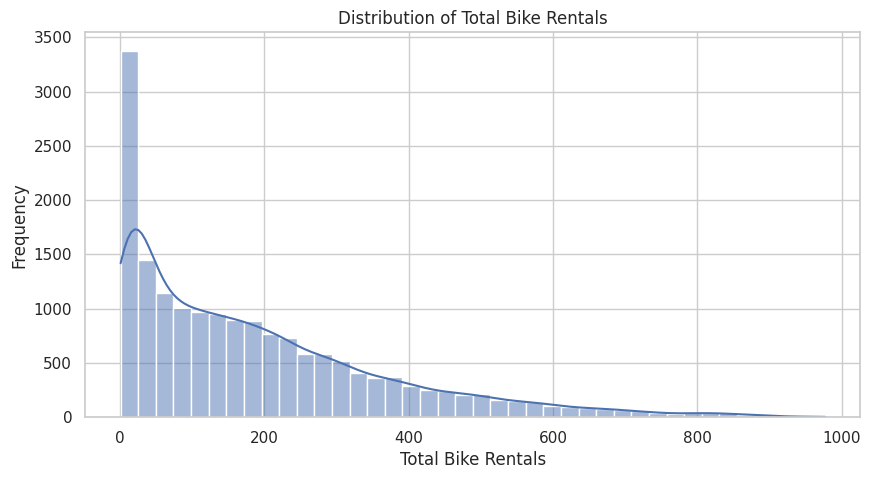

In [14]:

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="cnt", bins=40, kde=True)

plt.title("Distribution of Total Bike Rentals")
plt.xlabel("Total Bike Rentals")
plt.ylabel("Frequency")
plt.show()


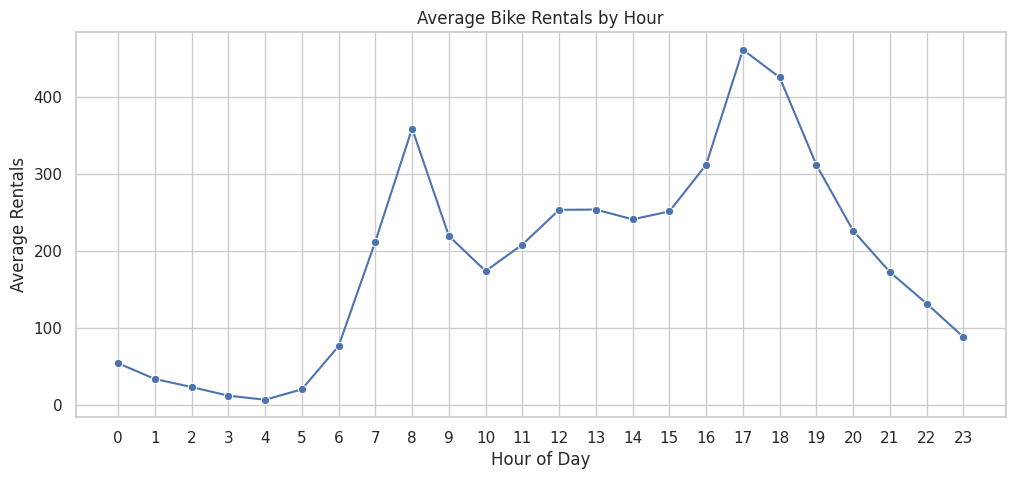

In [15]:

hourly_demand = df.groupby("hr")["cnt"].mean()

plt.figure(figsize=(12, 5))
sns.lineplot(
    x=hourly_demand.index,
    y=hourly_demand.values,
    marker="o"
)

plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Rentals")
plt.xticks(range(24))
plt.show()


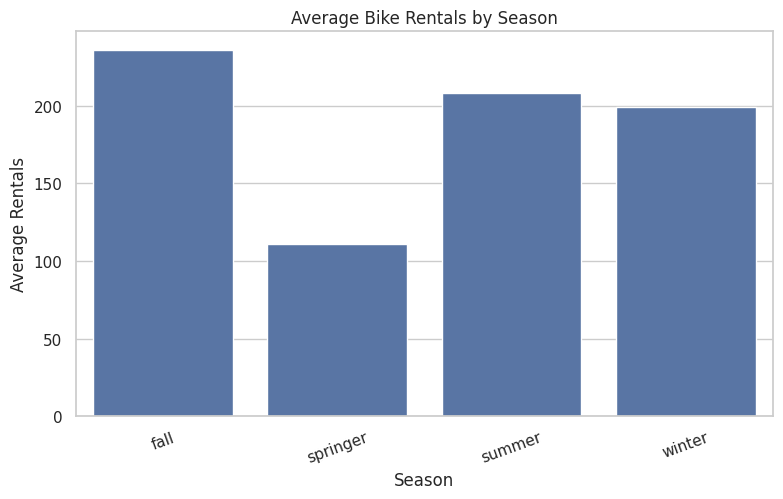

In [16]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="season",
    y="cnt",
    errorbar=None,
    order=sorted(df["season"].dropna().unique())
)

plt.title("Average Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Rentals")
plt.xticks(rotation=20)
plt.show()


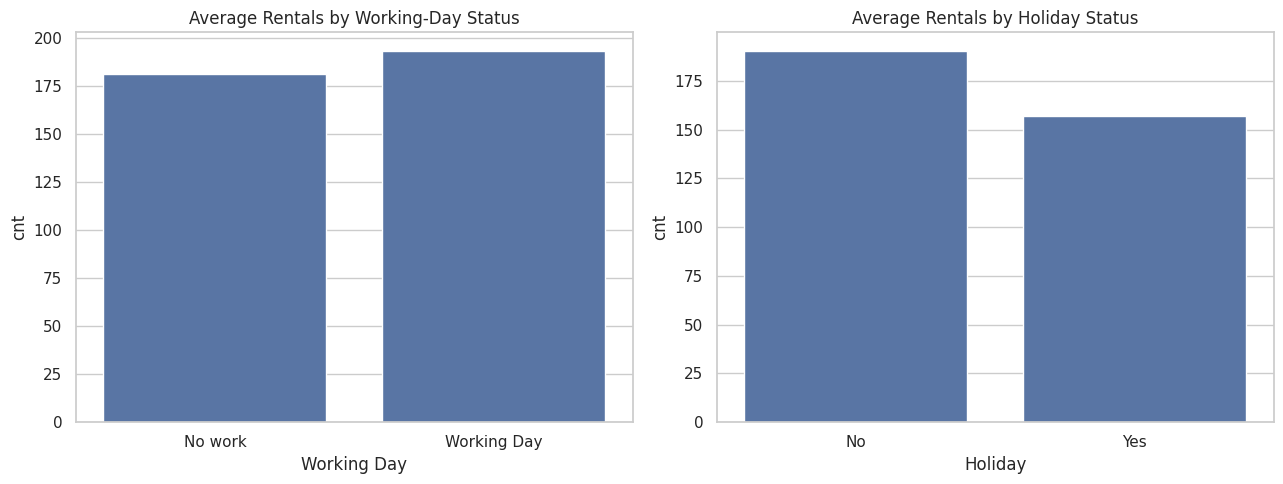

In [17]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=df, x="workingday", y="cnt",
    errorbar=None, ax=axes[0]
)
axes[0].set_title("Average Rentals by Working-Day Status")
axes[0].set_xlabel("Working Day")

sns.barplot(
    data=df, x="holiday", y="cnt",
    errorbar=None, ax=axes[1]
)
axes[1].set_title("Average Rentals by Holiday Status")
axes[1].set_xlabel("Holiday")

plt.tight_layout()
plt.show()


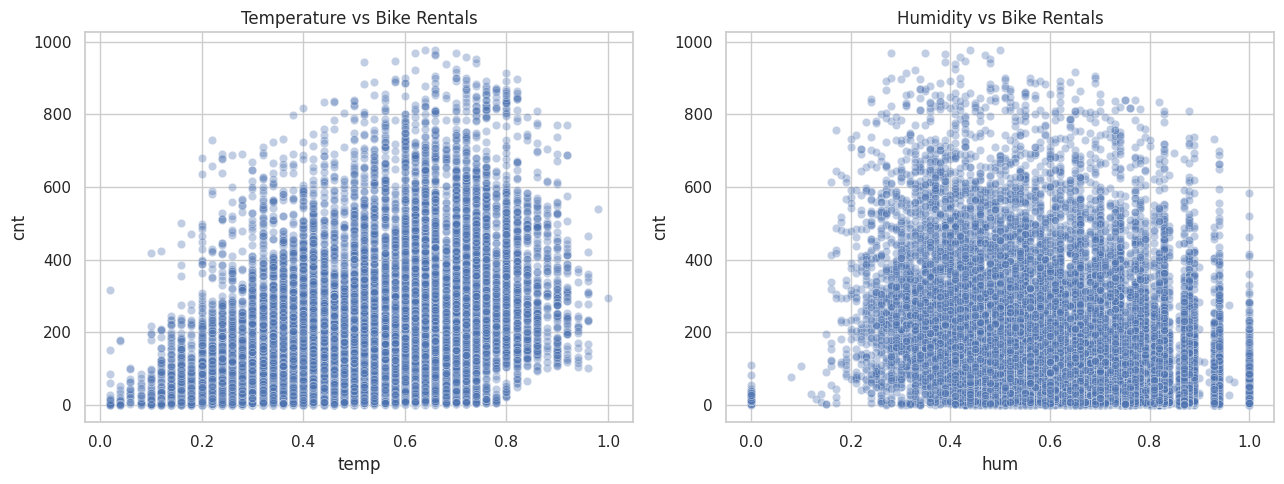

In [18]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=df, x="temp", y="cnt", alpha=0.35, ax=axes[0])
axes[0].set_title("Temperature vs Bike Rentals")

sns.scatterplot(data=df, x="hum", y="cnt", alpha=0.35, ax=axes[1])
axes[1].set_title("Humidity vs Bike Rentals")

plt.tight_layout()
plt.show()


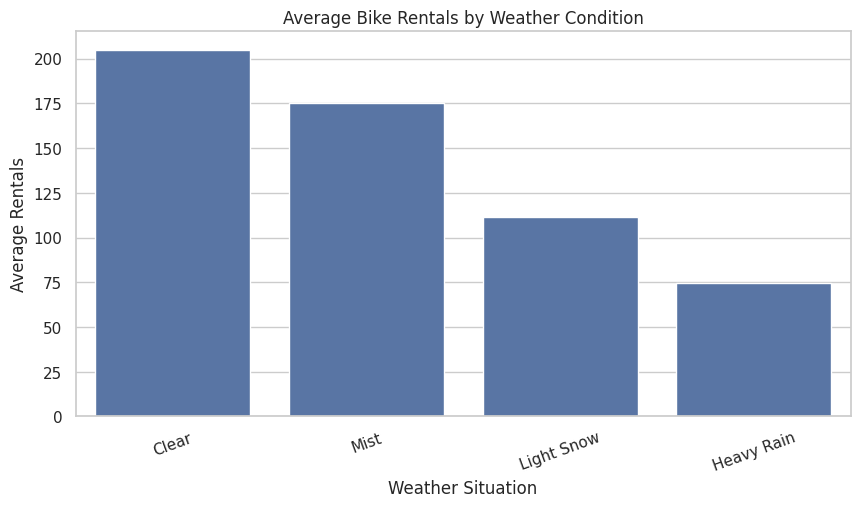

In [19]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="weathersit",
    y="cnt",
    errorbar=None
)

plt.title("Average Bike Rentals by Weather Condition")
plt.xlabel("Weather Situation")
plt.ylabel("Average Rentals")
plt.xticks(rotation=20)
plt.show()


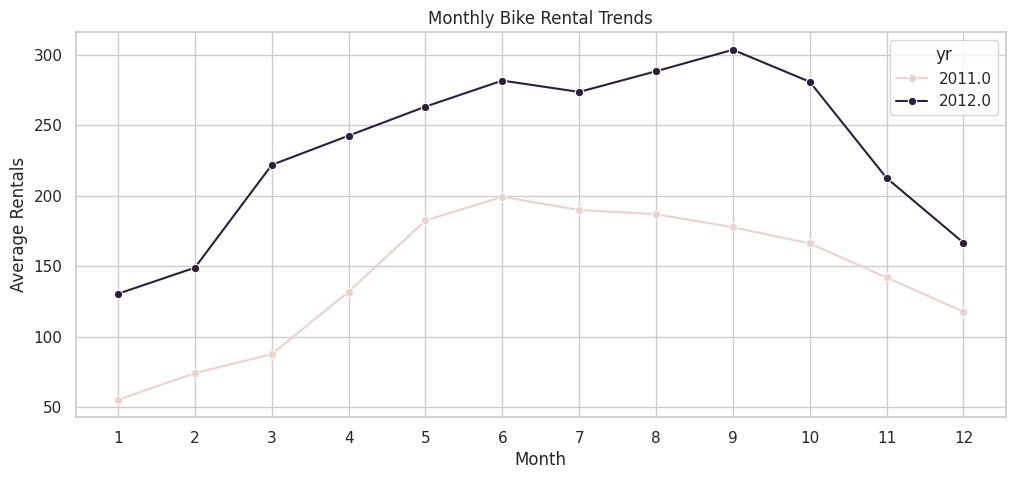

In [20]:

monthly_demand = (
    df.groupby(["yr", "mnth"])["cnt"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_demand,
    x="mnth",
    y="cnt",
    hue="yr",
    marker="o"
)

plt.title("Monthly Bike Rental Trends")
plt.xlabel("Month")
plt.ylabel("Average Rentals")
plt.xticks(range(1, 13))
plt.show()


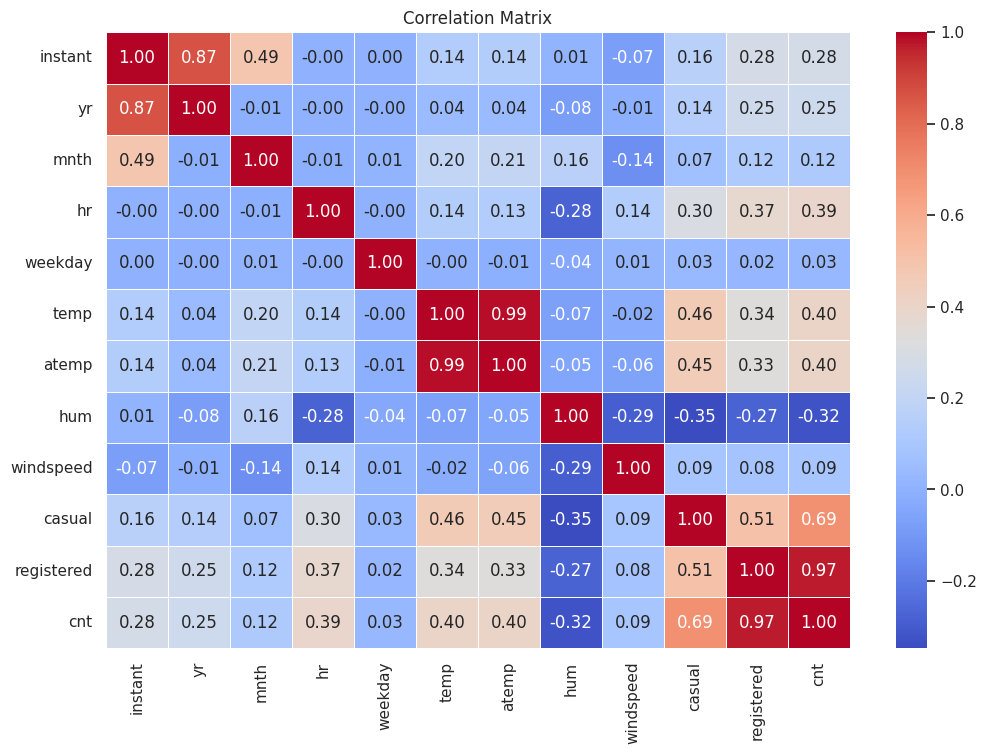

Correlation with total rentals:


,Correlation with cnt
cnt,1.000000
registered,0.972150
casual,0.694567
temp,0.404557
atemp,0.400912
hr,0.394071
instant,0.278379
yr,0.250483
mnth,0.120659
windspeed,0.093337


In [21]:

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.show()

print("Correlation with total rentals:")
display(
    numeric_df.corr()["cnt"]
    .sort_values(ascending=False)
    .to_frame("Correlation with cnt")
)


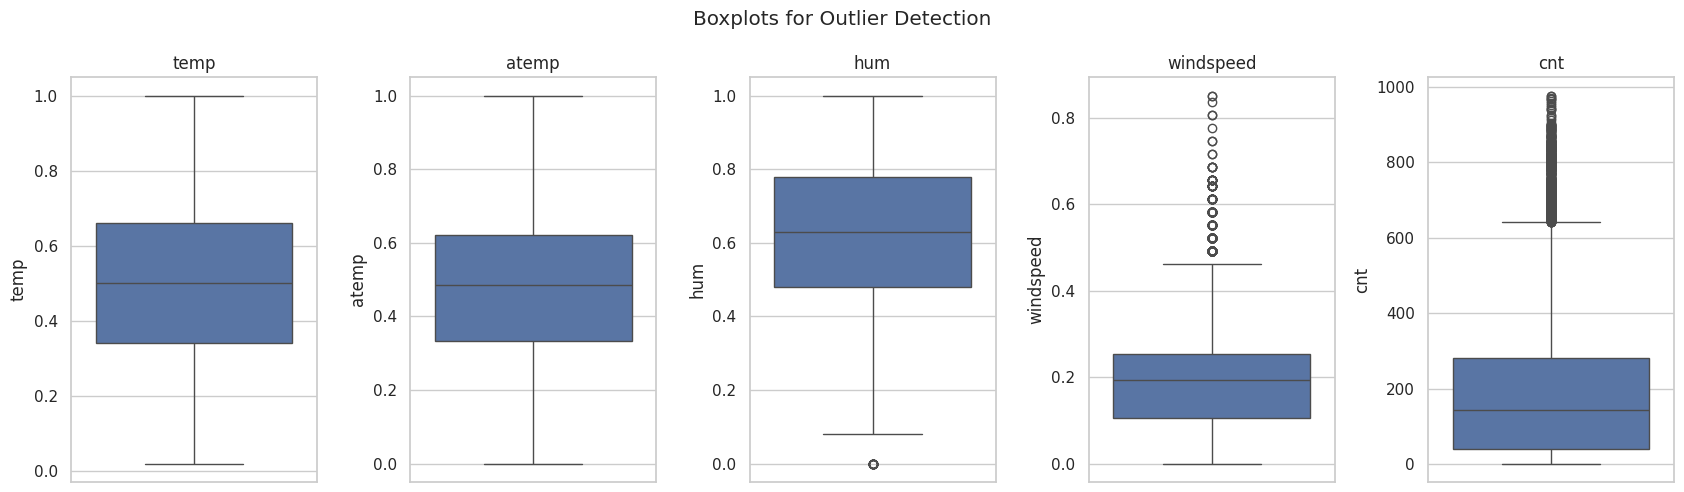

In [22]:

outlier_columns = ["temp", "atemp", "hum", "windspeed", "cnt"]

fig, axes = plt.subplots(1, 5, figsize=(17, 5))

for ax, col in zip(axes, outlier_columns):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)

plt.suptitle("Boxplots for Outlier Detection")
plt.tight_layout()
plt.show()


In [23]:

df["day"] = df["dteday"].dt.day

df["season"] = df["season"].replace({
    "springer": "spring"
})

print("Season categories:")
print(df["season"].value_counts(dropna=False))

print("\nNew features:")
display(df[["dteday", "day", "season", "hr", "cnt"]].head())


Season categories:
season
fall      4496
summer    4409
spring    4236
winter    4232
NaN          6
Name: count, dtype: int64

New features:


,dteday,day,season,hr,cnt
0,2011-01-01,1,spring,0,16
1,2011-01-01,1,spring,1,40
2,2011-01-01,1,spring,2,32
3,2011-01-01,1,spring,3,13
4,2011-01-01,1,spring,4,1


In [24]:

target = "cnt"

drop_columns = [
    "cnt",
    "instant",
    "dteday",
    "casual",
    "registered"
]

X = df.drop(columns=drop_columns)
y = df[target]

categorical_features = [
    "season", "yr", "mnth", "hr",
    "holiday", "weekday", "workingday", "weathersit"
]

numerical_features = [
    "temp", "atemp", "hum", "windspeed", "day"
]

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nCategorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

display(X.head())


Input feature shape: (17379, 13)
Target shape: (17379,)

Categorical features:
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit']

Numerical features:
['temp', 'atemp', 'hum', 'windspeed', 'day']


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,day
0,spring,2011.0,1.0,0,No,6,No work,Clear,0.24,0.2879,0.81,0.0,1
1,spring,2011.0,1.0,1,No,6,No work,Clear,0.22,0.2727,0.80,0.0,1
2,spring,2011.0,1.0,2,No,6,No work,Clear,0.22,0.2727,NaN,0.0,1
3,spring,2011.0,1.0,3,No,6,No work,Clear,0.24,0.2879,0.75,0.0,1
4,spring,2011.0,1.0,4,No,6,No work,Clear,0.24,0.2879,0.75,0.0,1


In [25]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])


Training rows: 13903
Testing rows: 3476


In [26]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


Model Building

In [27]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from sklearn.linear_model import LinearRegression
from sklearn.base import clone

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Histogram Gradient Boosting": HistGradientBoostingRegressor(
        random_state=42
    )
}

print("Number of models:", len(models))

for name in models:
    print(name)


Number of models: 6
Linear Regression
Decision Tree
Random Forest
Gradient Boosting
Extra Trees
Histogram Gradient Boosting


In [28]:

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(f"{name} trained successfully.")

print("\nAll six models have been trained.")


Linear Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.
Gradient Boosting trained successfully.
Extra Trees trained successfully.
Histogram Gradient Boosting trained successfully.

All six models have been trained.


Evaluation

In [29]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

results = []
predictions = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(results_df.round(4))


,Model,MAE,MSE,RMSE,R2 Score
0,Extra Trees,26.3663,2000.8893,44.7313,0.9368
1,Histogram Gradient Boosting,29.9765,2045.3115,45.2251,0.9354
2,Random Forest,29.7333,2243.3461,47.3640,0.9292
3,Decision Tree,40.5055,4623.3018,67.9949,0.8540
4,Gradient Boosting,57.8497,6381.9652,79.8872,0.7985
5,Linear Regression,74.0787,10086.0123,100.4291,0.6815


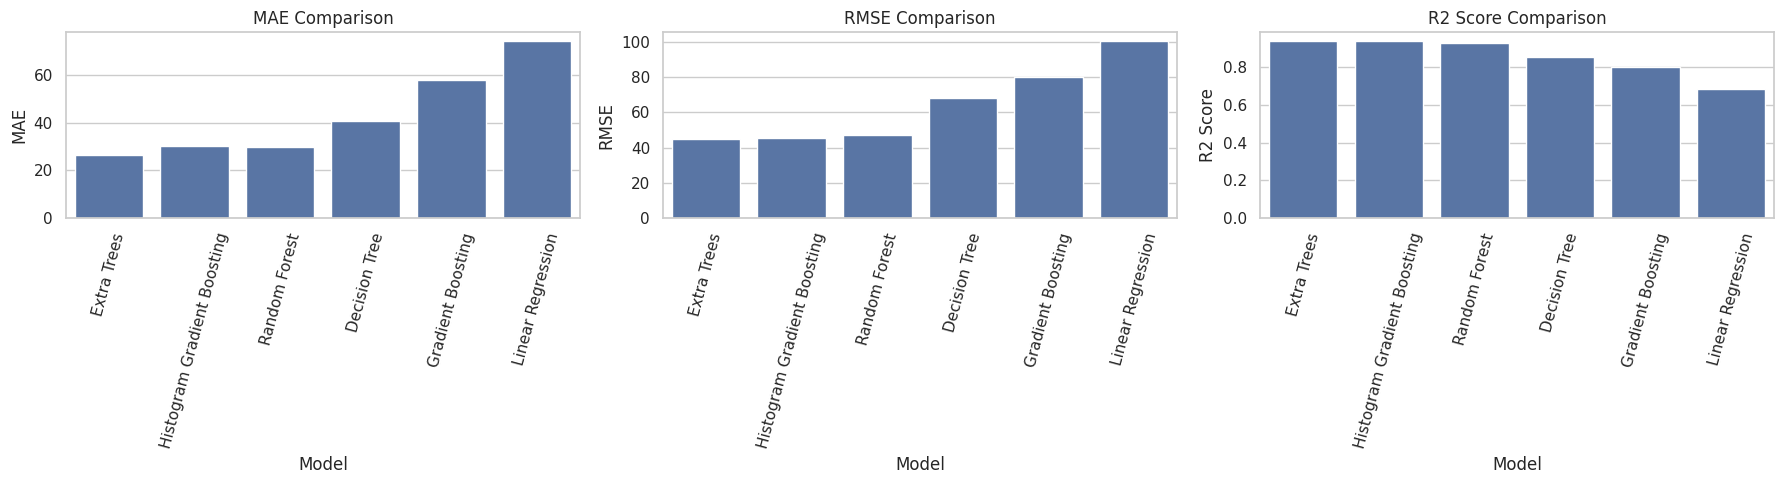

In [30]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=results_df, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("MAE Comparison")

sns.barplot(data=results_df, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("RMSE Comparison")

sns.barplot(data=results_df, x="Model", y="R2 Score", ax=axes[2])
axes[2].set_title("R2 Score Comparison")

for ax in axes:
    ax.tick_params(axis="x", rotation=75)

plt.tight_layout()
plt.show()


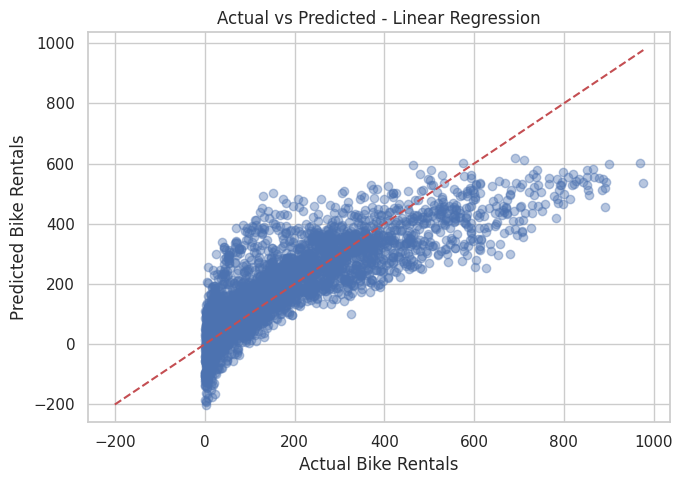

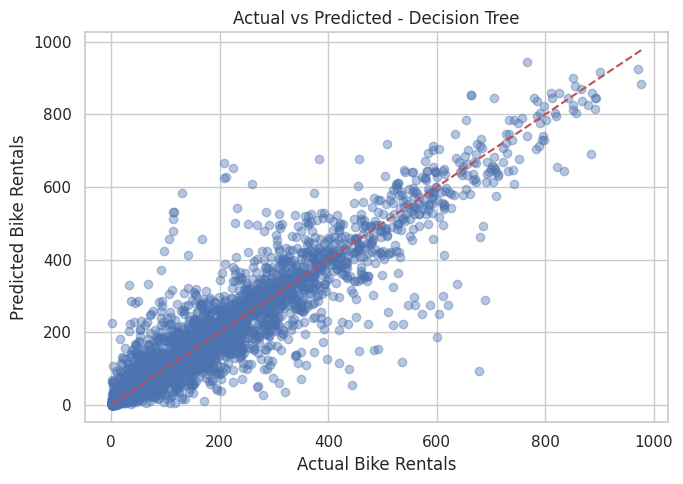

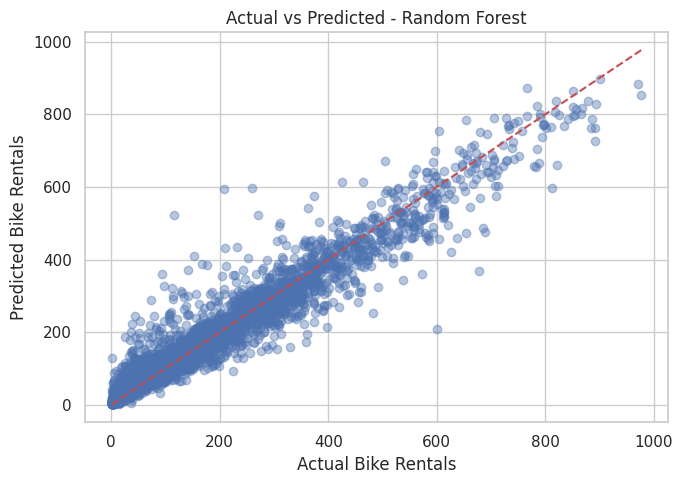

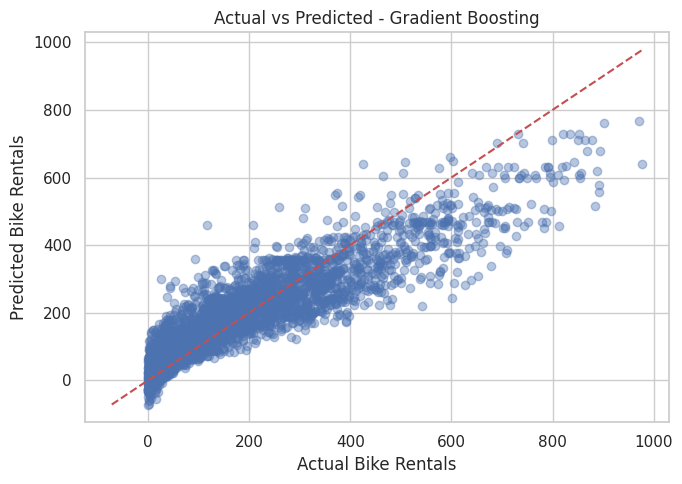

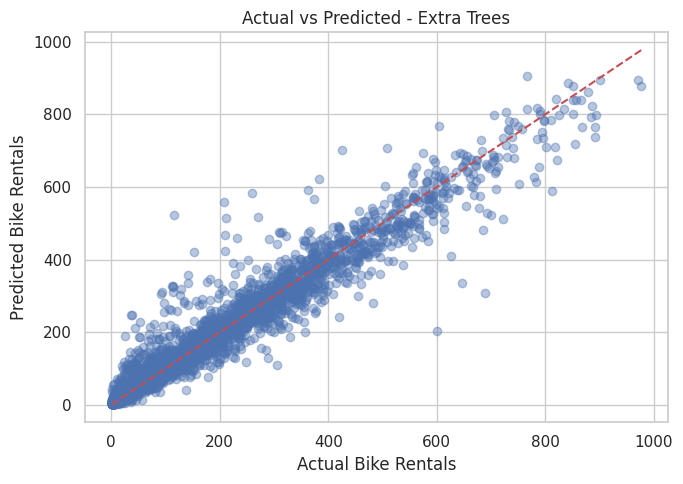

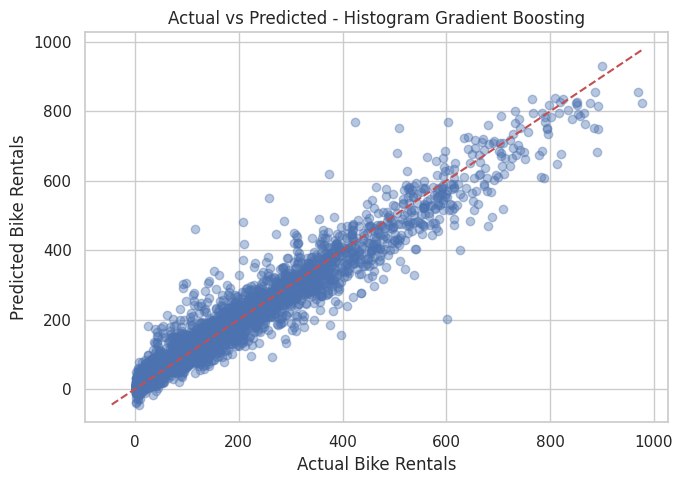

In [31]:

for name, y_pred in predictions.items():
    plt.figure(figsize=(7, 5))

    plt.scatter(y_test, y_pred, alpha=0.4)

    lower = min(y_test.min(), y_pred.min())
    upper = max(y_test.max(), y_pred.max())

    plt.plot(
        [lower, upper],
        [lower, upper],
        "r--"
    )

    plt.xlabel("Actual Bike Rentals")
    plt.ylabel("Predicted Bike Rentals")
    plt.title(f"Actual vs Predicted - {name}")

    plt.tight_layout()
    plt.show()


Best Model

In [32]:

best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("Best model based on lowest test RMSE:")
print(best_model_name)

print("\nEvaluation metrics:")
display(
    results_df.iloc[[0]].round(4)
)

print("\nComplete model ranking:")

for rank, row in enumerate(results_df.itertuples(index=False), start=1):
    print(
        f"{rank}. {row.Model} | "
        f"MAE: {row.MAE:.4f} | "
        f"RMSE: {row.RMSE:.4f} | "
        f"R2: {row._4:.4f}"
    )


Best model based on lowest test RMSE:
Extra Trees

Evaluation metrics:


,Model,MAE,MSE,RMSE,R2 Score
0,Extra Trees,26.3663,2000.8893,44.7313,0.9368



Complete model ranking:
1. Extra Trees | MAE: 26.3663 | RMSE: 44.7313 | R2: 0.9368
2. Histogram Gradient Boosting | MAE: 29.9765 | RMSE: 45.2251 | R2: 0.9354
3. Random Forest | MAE: 29.7333 | RMSE: 47.3640 | R2: 0.9292
4. Decision Tree | MAE: 40.5055 | RMSE: 67.9949 | R2: 0.8540
5. Gradient Boosting | MAE: 57.8497 | RMSE: 79.8872 | R2: 0.7985
6. Linear Regression | MAE: 74.0787 | RMSE: 100.4291 | R2: 0.6815


In [35]:

from sklearn.model_selection import GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import pandas as pd
import numpy as np
import joblib
import os


In [36]:

tuning_models = {
    "Decision Tree": (
        DecisionTreeRegressor(random_state=42),
        {
            "model__max_depth": [10, 20, None],
            "model__min_samples_split": [2, 10],
            "model__min_samples_leaf": [1, 5]
        }
    ),
    "Random Forest": (
        RandomForestRegressor(random_state=42, n_jobs=-1),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [20, None],
            "model__min_samples_leaf": [1, 3]
        }
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=42),
        {
            "model__n_estimators": [100, 200],
            "model__learning_rate": [0.05, 0.1],
            "model__max_depth": [2, 3]
        }
    ),
    "Extra Trees": (
        ExtraTreesRegressor(random_state=42, n_jobs=-1),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [20, None],
            "model__min_samples_split": [2, 10],
            "model__min_samples_leaf": [1, 3]
        }
    )
}


In [37]:

tuned_models = {}
tuning_results = []

cv = KFold(n_splits=3, shuffle=True, random_state=42)

for name, (model, params) in tuning_models.items():
    print(f"Tuning {name}...")

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=params,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    tuned_models[name] = grid_search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV RMSE": -grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })

tuning_results_df = pd.DataFrame(tuning_results)
tuning_results_df = tuning_results_df.sort_values(
    "Best CV RMSE"
).reset_index(drop=True)

display(tuning_results_df)


Tuning Decision Tree...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Tuning Random Forest...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Tuning Gradient Boosting...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Tuning Extra Trees...
Fitting 3 folds for each of 16 candidates, totalling 48 fits


,Model,Best CV RMSE,Best Parameters
0,Extra Trees,47.513466,"{'model__max_depth': None, 'model__min_samples..."
1,Random Forest,54.118846,"{'model__max_depth': None, 'model__min_samples..."
2,Decision Tree,68.906023,"{'model__max_depth': None, 'model__min_samples..."
3,Gradient Boosting,69.115291,"{'model__learning_rate': 0.1, 'model__max_dept..."


In [39]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tuned_evaluation = []
tuned_predictions = {}

for name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    tuned_predictions[name] = y_pred

    tuned_evaluation.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    })

tuned_results_df = pd.DataFrame(tuned_evaluation)
tuned_results_df = tuned_results_df.sort_values(
    "RMSE"
).reset_index(drop=True)

display(tuned_results_df.round(4))


,Model,MAE,RMSE,R2 Score
0,Extra Trees,26.2689,44.7244,0.9368
1,Random Forest,29.5090,47.0645,0.9300
2,Decision Tree,38.6897,64.3588,0.8692
3,Gradient Boosting,46.8197,66.2960,0.8612


In [40]:

baseline_results = results_df.copy()
baseline_results["Stage"] = "Baseline"

tuned_comparison = tuned_results_df.copy()
tuned_comparison["Stage"] = "Tuned"

comparison_df = pd.concat(
    [baseline_results, tuned_comparison],
    ignore_index=True
)

display(
    comparison_df.sort_values("RMSE")[
        ["Model", "Stage", "MAE", "RMSE", "R2 Score"]
    ].round(4)
)


,Model,Stage,MAE,RMSE,R2 Score
6,Extra Trees,Tuned,26.2689,44.7244,0.9368
0,Extra Trees,Baseline,26.3663,44.7313,0.9368
1,Histogram Gradient Boosting,Baseline,29.9765,45.2251,0.9354
7,Random Forest,Tuned,29.5090,47.0645,0.9300
2,Random Forest,Baseline,29.7333,47.3640,0.9292
8,Decision Tree,Tuned,38.6897,64.3588,0.8692
9,Gradient Boosting,Tuned,46.8197,66.2960,0.8612
3,Decision Tree,Baseline,40.5055,67.9949,0.8540
4,Gradient Boosting,Baseline,57.8497,79.8872,0.7985
5,Linear Regression,Baseline,74.0787,100.4291,0.6815


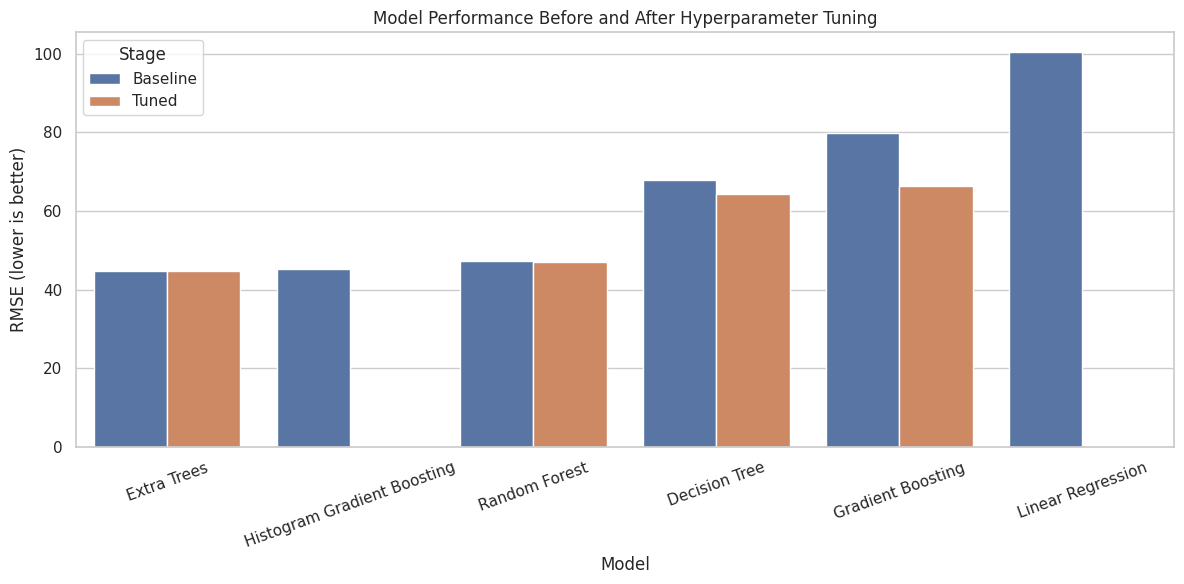

In [41]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="RMSE",
    hue="Stage"
)

plt.title("Model Performance Before and After Hyperparameter Tuning")
plt.xlabel("Model")
plt.ylabel("RMSE (lower is better)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [42]:

all_results = pd.concat(
    [
        results_df.assign(Stage="Baseline"),
        tuned_results_df.assign(Stage="Tuned")
    ],
    ignore_index=True
)

best_row = all_results.loc[all_results["RMSE"].idxmin()]

best_model_name = best_row["Model"]
best_stage = best_row["Stage"]

if best_stage == "Tuned":
    final_model = tuned_models[best_model_name]
else:
    final_model = trained_models[best_model_name]

print("Best model:", best_model_name)
print("Stage:", best_stage)
print("MAE:", round(best_row["MAE"], 4))
print("RMSE:", round(best_row["RMSE"], 4))
print("R2 Score:", round(best_row["R2 Score"], 4))


Best model: Extra Trees
Stage: Tuned
MAE: 26.2689
RMSE: 44.7244
R2 Score: 0.9368


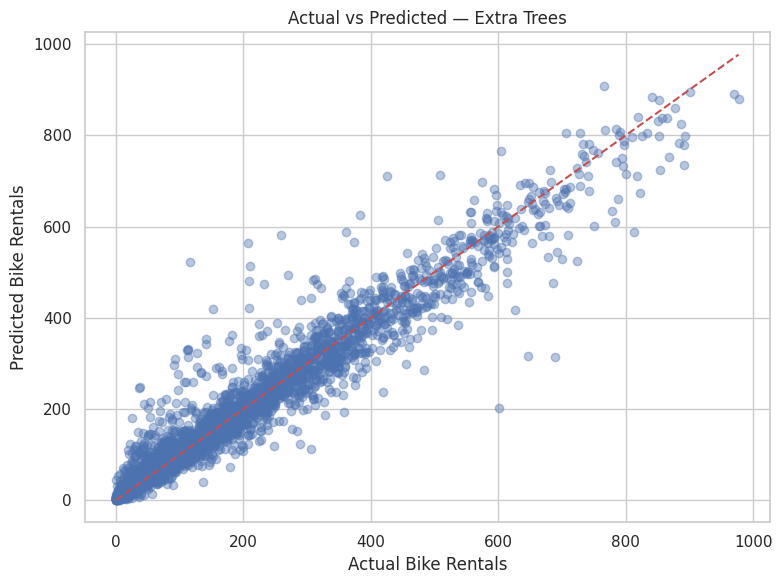

In [43]:

final_predictions = final_model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, final_predictions, alpha=0.4)

minimum = min(y_test.min(), final_predictions.min())
maximum = max(y_test.max(), final_predictions.max())

plt.plot([minimum, maximum], [minimum, maximum], "r--")
plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.tight_layout()
plt.show()


In [44]:

os.makedirs("bike_rental_model", exist_ok=True)

model_path = "bike_rental_model/best_bike_rental_model.joblib"

joblib.dump(final_model, model_path)

print("Model saved successfully:", model_path)


Model saved successfully: bike_rental_model/best_bike_rental_model.joblib


In [45]:

loaded_model = joblib.load(model_path)

sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)[0]
actual = y_test.iloc[0]

print("Predicted bike rentals:", round(prediction, 2))
print("Actual bike rentals:", actual)
print("Absolute error:", round(abs(actual - prediction), 2))


Predicted bike rentals: 378.93
Actual bike rentals: 425
Absolute error: 46.07


In [46]:

comparison_df.to_csv(
    "bike_rental_model_comparison.csv",
    index=False
)

prediction_df = pd.DataFrame({
    "Actual Rentals": y_test.to_numpy(),
    "Predicted Rentals": final_predictions
})

prediction_df.to_csv(
    "bike_rental_predictions.csv",
    index=False
)

print("Comparison and prediction files exported.")


Comparison and prediction files exported.


In [47]:

import joblib
import os

os.makedirs("bike_rental_deployment", exist_ok=True)

joblib.dump(
    final_model,
    "bike_rental_deployment/best_bike_rental_model.joblib"
)

print("Model saved successfully!")


Model saved successfully!


In [48]:

%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
from pathlib import Path

st.set_page_config(page_title="Bike Rental Prediction", page_icon="🚲")

@st.cache_resource
def load_model():
    return joblib.load(
        Path(__file__).parent / "best_bike_rental_model.joblib"
    )

model = load_model()

st.title("🚲 Bike-Sharing Rental Prediction")
st.write("Enter the details below to predict the expected rental count.")

with st.form("prediction_form"):
    season = st.selectbox(
        "Season", ["spring", "summer", "fall", "winter"]
    )
    yr = st.selectbox("Year", [0, 1], format_func=lambda x: 2011 + x)
    mnth = st.selectbox("Month", list(range(1, 13)))
    hr = st.slider("Hour", 0, 23, 8)
    holiday = st.selectbox("Holiday", [0, 1])
    weekday = st.selectbox("Weekday (0–6)", list(range(7)))
    workingday = st.selectbox("Working day", [0, 1])
    weathersit = st.selectbox("Weather situation", [1, 2, 3, 4])

    temp = st.slider("Temperature (dataset scale)", 0.0, 1.0, 0.5)
    atemp = st.slider("Apparent temperature (dataset scale)", 0.0, 1.0, 0.5)
    hum = st.slider("Humidity (dataset scale)", 0.0, 1.0, 0.6)
    windspeed = st.slider("Windspeed (dataset scale)", 0.0, 1.0, 0.2)
    day = st.slider("Day of month", 1, 31, 15)

    submitted = st.form_submit_button("Predict Rentals")

if submitted:
    input_data = pd.DataFrame([{
        "season": season,
        "yr": yr,
        "mnth": mnth,
        "hr": hr,
        "holiday": holiday,
        "weekday": weekday,
        "workingday": workingday,
        "weathersit": weathersit,
        "temp": temp,
        "atemp": atemp,
        "hum": hum,
        "windspeed": windspeed,
        "day": day
    }])

    try:
        prediction = max(0, float(model.predict(input_data)[0]))
        st.success(f"Estimated bike rentals: {prediction:,.0f}")
        with st.expander("View input details"):
            st.dataframe(input_data, use_container_width=True)
    except Exception as error:
        st.error(f"Prediction failed: {error}")
        st.write(
            "Check that the feature names, categories, and data scales "
            "match those used to train your model."
        )

st.caption("Machine Learning project • Bike Rental Demand Prediction")


Writing app.py
